## Centrality Measures

> **Core idea:** "Centrality" measures *how important* a node is — but different definitions of "important" give different centrality measures. A node important by one measure may be unimportant by another.

We will use **one shared example graph** throughout this section so you can directly compare how the same nodes rank differently.

### The Star-Plus-Triangle Example Network

```
        Center
       /  |  \
     A1   A2  Bridge
               |    \
              B1 -- B2
```

- **Center** connects to A1, A2, and Bridge.
- **Bridge** connects Center's cluster to B1–B2's cluster.
- **B1** and **B2** form a small tight cluster.

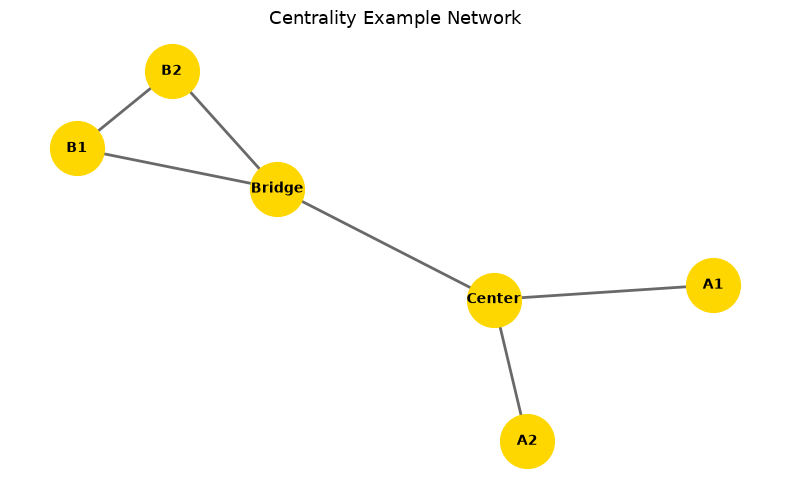

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
C = nx.Graph()

C.add_edges_from([
    ("Center", "A1"),
    ("Center", "A2"),
    ("Center", "Bridge"),
    ("Bridge", "B1"),
    ("Bridge", "B2"),
    ("B1",     "B2"),
]
)

# Visualize
plt.figure(figsize=(8, 5))
pos = nx.spring_layout(C, seed=10)
nx.draw_networkx(
    C, pos,
    node_color="gold",
    node_size=1500,
    font_size=10,
    font_weight="bold",
    edge_color="dimgray",
    width=2,
)
plt.title("Centrality Example Network", fontsize=13)
plt.axis("off")
plt.tight_layout()
plt.show()


## Degree Centrality

- What it measures: How many direct connections a node has, normalized by the maximum possible connections
- **Formula**: degree_centrality(v) = degree(v) / (N -1) where N is the number of nodes
- **Range:** 0.0 (no connections) to 1.0 (connected to every other node).

**Intuition:** A node with high degree centrality is a **local hub** — many people or things connect directly to it.

**Limitation:** Degree centrality ignores the *quality* of connections. Being connected to 10 isolated nodes is very different from being connected to 10 well-connected hubs.

In [2]:
deg_cenrality = nx.degree_centrality(C)

print("=" * 55)
print("DEGREE CENTRALITY")
print("=" * 55)
print(f"{'Node':10s}  {'Degree':8s}  {'Centrality':12s}  Interpretation")
print("-" * 70)

deg_cenrality


for node, score in deg_cenrality.items():
    print(f"{node:10s}  {C.degree(node):8d}  {score:12.3f}  {score * 100:6.2f}%")

DEGREE CENTRALITY
Node        Degree    Centrality    Interpretation
----------------------------------------------------------------------
Center             3         0.600   60.00%
A1                 1         0.200   20.00%
A2                 1         0.200   20.00%
Bridge             3         0.600   60.00%
B1                 2         0.400   40.00%
B2                 2         0.400   40.00%


## Betweness Centrality

- What it measures: How often a node appears on the shortest path between other pairs of nodes
- **Intuition**: A node with high betweeness is a broker or gatekeeper
- **Formula:**
$$BC(v) = \sum_{s \ne v \ne t} \frac{\sigma_{st}(v)}{\sigma_{st}}$$

Where:
- $\sigma_{st}$ = total number of shortest paths from node s to node t
- $\sigma_{st}(v)$ = number of those paths that pass through v

**Range (normalized):** 0.0 to 1.0

**High betweenness:** Node is a critical intermediary.
**Low betweenness:** Node rarely appears on shortest paths between others.

In [3]:
bet_centrality = nx.betweenness_centrality(C, normalized=True)

print("=" * 60)
print("BETWEENNESS CENTRALITY")
print("=" * 60)
print(f"{'Node':10s}  {'Betweenness':12s}  Interpretation")
print("-" * 65)

interpretations = {
    "Center":  "Connects A1, A2 to the rest — moderate broker",
    "Bridge":  "THE critical broker — only link between two clusters",
    "A1":      "Leaf node — never on any shortest path between others",
    "A2":      "Leaf node — never on any shortest path between others",
    "B1":      "Minor broker within B cluster",
    "B2":      "Minor broker within B cluster",
}

for node, score in sorted(bet_centrality.items()):
    interp = interpretations.get(node, "")
    print(f"{node:10s}  {score:12.4f}  {interp}")

BETWEENNESS CENTRALITY
Node        Betweenness   Interpretation
-----------------------------------------------------------------
A1                0.0000  Leaf node — never on any shortest path between others
A2                0.0000  Leaf node — never on any shortest path between others
B1                0.0000  Minor broker within B cluster
B2                0.0000  Minor broker within B cluster
Bridge            0.6000  THE critical broker — only link between two clusters
Center            0.7000  Connects A1, A2 to the rest — moderate broker


### Closeness Centrality

**What it measures:** How quickly a node can reach **all other nodes** in the graph.

**Intuition:** A node with high closeness can **spread information efficiently** — it is close to everyone, so messages spread fast from it.

**Formula:**
$$CC(v) = \frac{N-1}{\sum_{u \ne v} d(v, u)}$$

Where $d(v, u)$ is the shortest path length between v and u.

**Range:** 0.0 to 1.0. Higher = closer to center of graph.

**Low closeness:** Node is on the periphery, far from most others.

In [4]:
close_centrality = nx.closeness_centrality(C)

print("=" * 60)
print("CLOSENESS CENTRALITY")
print("=" * 60)
print(f"{'Node':10s}  {'Closeness':12s}  Interpretation")
print("-" * 65)

for node, score in sorted(close_centrality.items()):
    print(f"{node:10s}  {score:12.4f}")

CLOSENESS CENTRALITY
Node        Closeness     Interpretation
-----------------------------------------------------------------
A1                0.4545
A2                0.4545
B1                0.5000
B2                0.5000
Bridge            0.7143
Center            0.7143


### Eigenvector Centrality

**What it measures:** A node's importance based on the **importance of its neighbors**. Being connected to important nodes makes you important.

**Intuition:** It is not just about *how many* connections you have, but *who* you are connected to. One connection to a very influential node can be worth more than ten connections to unimportant nodes.

**Mathematical basis:** The centrality score of each node equals a weighted sum of the scores of its neighbors. This is solved iteratively as an eigenvector equation — hence the name.

**Range:** 0.0 to 1.0 (normalized).

### PageRank

**What it measures:** Originally designed by Google for ranking webpages. A node's PageRank represents the probability that a random walker (following edges randomly) is at that node at any given time.

**Key difference from eigenvector centrality:** PageRank uses a **damping factor** (typically 0.85) — the walker occasionally teleports to a random node rather than always following edges. This prevents certain graph structures from dominating the scores.

In [5]:
# ─────────────────────────────────────────────────────────────────────────────
# EIGENVECTOR CENTRALITY and PAGERANK
# Note: Both are designed for directed graphs (PageRank especially).
# We use our undirected graph for illustration — results are still valid.
# ─────────────────────────────────────────────────────────────────────────────
eig_centrality  = nx.eigenvector_centrality(C, max_iter=1000)
pagerank_scores = nx.pagerank(C, alpha=0.85)  # alpha = damping factor

print("=" * 70)
print("ALL FIVE CENTRALITY MEASURES — SIDE BY SIDE COMPARISON")
print("=" * 70)
print(f"{'Node':10s}  {'Degree':8s}  {'Betwn':8s}  {'Close':8s}  {'Eigen':8s}  {'PageRank':10s}")
print("-" * 70)

for node in sorted(C.nodes()):
    print(
        f"{node:10s}  "
        f"{deg_cenrality[node]:8.3f}  "
        f"{bet_centrality[node]:8.3f}  "
        f"{close_centrality[node]:8.3f}  "
        f"{eig_centrality[node]:8.3f}  "
        f"{pagerank_scores[node]:10.4f}"
    )

print("\n" + "=" * 70)
print("INTERPRETATION SUMMARY")
print("=" * 70)
print("""
• Center has HIGH degree centrality — it connects to the most nodes directly.
• Bridge has HIGH betweenness centrality — it is the ONLY path between the
  left cluster (Center, A1, A2) and the right cluster (B1, B2).
  Remove Bridge and the graph splits into two disconnected components.
• Center/Bridge have the highest closeness — they are most central geographically.
• A1, A2, B1, B2 (leaf/peripheral nodes) score LOW on all measures.
• The SAME node (Center) ranks #1 for degree but not necessarily #1 for betweenness.

→ This demonstrates why you must never use just ONE centrality measure.
  Use multiple measures and compare them to form a complete picture.
""")

ALL FIVE CENTRALITY MEASURES — SIDE BY SIDE COMPARISON
Node        Degree    Betwn     Close     Eigen     PageRank  
----------------------------------------------------------------------
A1             0.200     0.000     0.455     0.183      0.0978
A2             0.200     0.000     0.455     0.183      0.0978
B1             0.400     0.000     0.500     0.457      0.1577
B2             0.400     0.000     0.500     0.457      0.1577
Bridge         0.600     0.600     0.714     0.584      0.2319
Center         0.600     0.700     0.714     0.417      0.2570

INTERPRETATION SUMMARY

• Center has HIGH degree centrality — it connects to the most nodes directly.
• Bridge has HIGH betweenness centrality — it is the ONLY path between the
  left cluster (Center, A1, A2) and the right cluster (B1, B2).
  Remove Bridge and the graph splits into two disconnected components.
• Center/Bridge have the highest closeness — they are most central geographically.
• A1, A2, B1, B2 (leaf/peripheral nod

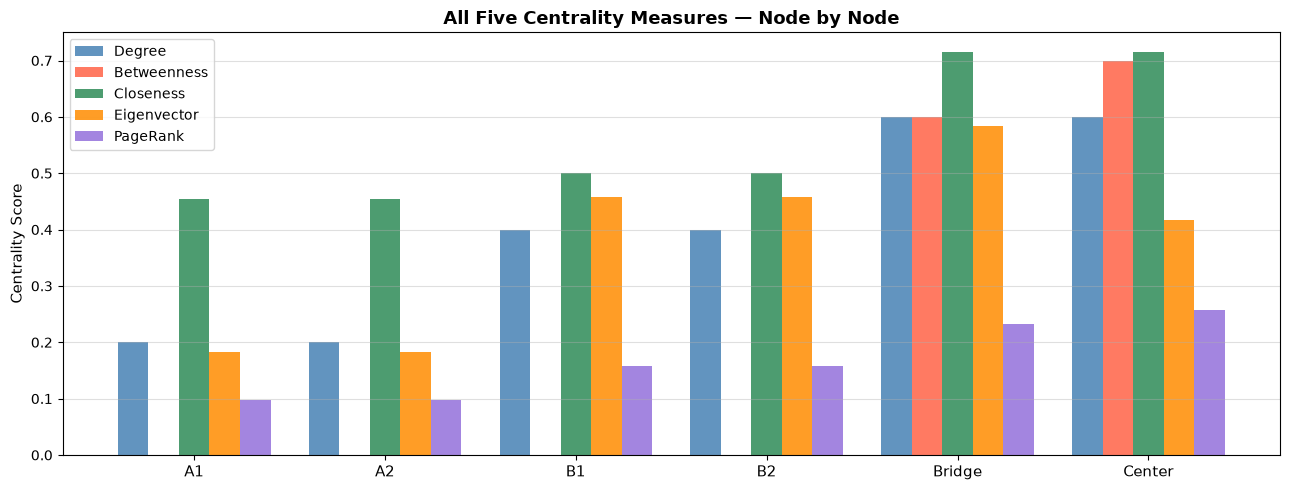

In [6]:
# ─────────────────────────────────────────────────────────────────────────────
# VISUALIZE all centrality scores as bar charts for easy comparison
# ─────────────────────────────────────────────────────────────────────────────
import numpy as np

nodes = sorted(C.nodes())
metrics = {
    "Degree":      [deg_cenrality[n]   for n in nodes],
    "Betweenness": [bet_centrality[n]   for n in nodes],
    "Closeness":   [close_centrality[n] for n in nodes],
    "Eigenvector": [eig_centrality[n]   for n in nodes],
    "PageRank":    [pagerank_scores[n]  for n in nodes],
}

colors = ["steelblue", "tomato", "seagreen", "darkorange", "mediumpurple"]
x = np.arange(len(nodes))
width = 0.16

fig, ax = plt.subplots(figsize=(13, 5))

for i, (metric_name, values) in enumerate(metrics.items()):
    ax.bar(x + i * width, values, width, label=metric_name, color=colors[i], alpha=0.85)

ax.set_xticks(x + width * 2)
ax.set_xticklabels(nodes, fontsize=11)
ax.set_ylabel("Centrality Score", fontsize=11)
ax.set_title("All Five Centrality Measures — Node by Node", fontsize=13, fontweight="bold")
ax.legend(fontsize=10)
ax.grid(axis="y", alpha=0.4)

plt.tight_layout()
plt.show()

| Centrality                 | Question it answers                                                          | What it measures                             | Looks at                                        | High score means...                                   | Simple real-world interpretation      |
| -------------------------- | ---------------------------------------------------------------------------- | -------------------------------------------- | ----------------------------------------------- | ----------------------------------------------------- | ------------------------------------- |
| **Degree Centrality**      | **"How many direct connections does this node have?"**                       | Number/proportion of direct connections      | Immediate neighbors                             | The node is highly connected                          | **Popular / well-connected person**   |
| **Betweenness Centrality** | **"How often does this node sit on the shortest path between other nodes?"** | Control/mediation of information flow        | Shortest paths through the node                 | The node can act as a **bridge or broker**            | **Middleman / gatekeeper**            |
| **Closeness Centrality**   | **"How quickly can this node reach all other nodes?"**                       | Average distance to other nodes              | Shortest paths **from the node to others**      | The node is close to many other nodes                 | **Can reach everyone quickly**        |
| **Eigenvector Centrality** | **"Is this node connected to other important nodes?"**                       | Importance based on neighbors' importance    | Node + its neighbors recursively                | The node is connected to **influential nodes**        | **Connected to the important people** |
| **PageRank**               | **"How important is this node based on who points to it?"**                  | Importance propagated through directed links | Incoming directed edges + importance of sources | The node receives strong "votes" from important nodes | **Highly endorsed / authoritative**   |
